# C0 · power recomputed from the measured variances (free analysis 1 of 4)

**Why.** The plan's power figures (§7) came from an invented error model: between-seed SD of log SD 0.05 and
landmark-to-landmark SD of α 0.10. The plan requires them to be recomputed from the real baselines before registration.
This notebook measures those inputs on the finished ISBI runs (High and Medium) and reruns the power simulation for the
remaining tests: P0a/P0b-type tests at ISBI, the tier comparison (P0e), the HTO and hand replications (P0c) and the
coupling arms (Q3).

**Inputs (no training, no GPU):** `arm_A_summary/arm_A_axis_observations.csv` of both tiers (written by §10 of the arm A
notebooks). Only usable cells (≤ 5 % gross failures in the oval and the paired B0 cell) and the primary decoder are used,
as in §10.

**Generative model used for the simulation.** For landmark i, seed s and target axis d:
Δ log SD = c_i + α_i · x + ε_oval − ε_B0(i, s, d), with x = log(σ_d/σ₀), α_i ~ N(α, τ²), and the two ε terms independent
N(0, σ_seed²). ε_B0 is shared by every oval run of the same seed, as in the real design. σ_seed is the measured between-seed
SD of log SD in the round baseline; τ is the between-landmark SD of α after removing estimation noise.

Status: exploratory (not part of the registered analysis); it only feeds the registration's power statement.

In [1]:
ANALYSIS = "power_measured"
import os, json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def _repo_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "weights").is_dir() and (q / "data").is_dir():
            return q
    return None

_REPO = _repo_root()
W_ROOT = Path(os.environ.get("C0_WEIGHTS", "/tf/weights/C0" if os.path.isdir("/tf/weights/C0") else str(_REPO / "weights" / "C0")))
OUT = W_ROOT / "analyses" / ANALYSIS
OUT.mkdir(parents=True, exist_ok=True)
PD = "quadratic"
TIERS = {"High": {"net": "UNet-64", "sigma0_px": 5.0, "protocol": "093467c2293e4792", "arm": "47b9c6388cce8c42"},
         "Medium": {"net": "UNet-32", "sigma0_px": 5.0 * 2 ** 0.5, "protocol": "09b9ae2a23fe2266", "arm": "6505f2d9c645689e"}}
COLORS = {"High": "#0072B2", "Medium": "#D55E00"}
MIN_OBS = 8

def load_obs(t):
    agg = W_ROOT / f"ISBI2015_{t}" / "arm_A_summary"
    pool = json.loads((agg / "alpha_pooled.json").read_text())
    assert pool["protocol_hash"] == TIERS[t]["protocol"] and pool["arm_hash"] == TIERS[t]["arm"], f"{t}: unexpected arm A analysis"
    o = pd.read_csv(agg / "arm_A_axis_observations.csv")
    o = o[o.decoder == PD].copy()
    o["usable"] = o.usable.astype(bool)
    return o

OBS = {t: load_obs(t) for t in TIERS}
print("W_ROOT", W_ROOT, "| observations per tier:", {t: len(o) for t, o in OBS.items()})

W_ROOT C:\Users\nearl\Desktop\probable-umbrella\weights\C0 | observations per tier: {'High': 912, 'Medium': 912}


## 1. Measured inputs

* **σ_seed:** SD across the three paired B0 seeds of log SD along each baseline axis (u, v), per landmark, pooled as the root
  mean square over landmark × axis (usable B0 cells only).
* **Residual SD of Δ log SD** around each landmark's α fit (the §10 model, intercept + slope), pooled. Under the generative
  model it should be close to √2 · σ_seed; the simulation is calibrated to the measured residual where the two differ.
* **τ:** between-landmark SD of α, τ² = var(α̂_i) − mean(SE_i²) (method of moments, floored at 0).
* **τ_d:** the same for the per-landmark difference α_i(Medium) − α_i(High), which sets the power of the paired P0e test.

In [2]:
def per_landmark_fits(o):
    rows = []
    for lm, g in o[o.usable].groupby("landmark"):
        if len(g) < MIN_OBS:
            continue
        X = np.column_stack([np.ones(len(g)), g.x.values])
        b, *_ = np.linalg.lstsq(X, g.dlog_sd.values, rcond=None)
        r = g.dlog_sd.values - X @ b
        dof = len(g) - 2
        s2 = r @ r / dof
        se = math.sqrt(s2 * np.linalg.inv(X.T @ X)[1, 1])
        rows.append({"landmark": lm, "alpha": b[1], "se": se, "resid_ss": r @ r, "dof": dof, "n_obs": len(g)})
    return pd.DataFrame(rows).set_index("landmark")

INPUTS, FITS = {}, {}
for t, o in OBS.items():
    b0 = o[(o.fail_b0 <= 0.05)].drop_duplicates(["seed", "landmark", "direction"])[["seed", "landmark", "direction", "sd_b0"]]
    sd_seed = b0.assign(l=np.log(b0.sd_b0)).groupby(["landmark", "direction"]).l.std(ddof=1)
    f = per_landmark_fits(o)
    FITS[t] = f
    tau2 = f.alpha.var(ddof=1) - (f.se ** 2).mean()
    INPUTS[t] = {"sigma_seed": float(np.sqrt((sd_seed ** 2).mean())), "sigma_seed_median": float(sd_seed.median()),
                 "resid_sd": float(np.sqrt(f.resid_ss.sum() / f.dof.sum())), "n_landmarks": int(len(f)),
                 "alpha_mean": float(f.alpha.mean()), "alpha_sd_observed": float(f.alpha.std(ddof=1)),
                 "mean_se_alpha": float(f.se.mean()), "tau": float(math.sqrt(max(tau2, 0.0)))}
common = FITS["High"].index.intersection(FITS["Medium"].index)
d = FITS["Medium"].alpha[common] - FITS["High"].alpha[common]
tau_d2 = d.var(ddof=1) - (FITS["Medium"].se[common] ** 2 + FITS["High"].se[common] ** 2).mean()
INPUTS["paired_difference"] = {"n_landmarks": int(len(common)), "mean_diff": float(d.mean()), "sd_diff_observed": float(d.std(ddof=1)),
                               "tau_d": float(math.sqrt(max(tau_d2, 0.0)))}
INPUTS["plan_assumed"] = {"sigma_seed": 0.05, "tau": 0.10}
(OUT / "power_inputs_measured.json").write_text(json.dumps(INPUTS, indent=1))
pd.DataFrame({k: v for k, v in INPUTS.items() if k in TIERS}).round(4)

,High,Medium
sigma_seed,0.0457,0.0436
sigma_seed_median,0.0273,0.0303
resid_sd,0.0760,0.0753
n_landmarks,15.0000,15.0000
alpha_mean,0.0642,0.0850
alpha_sd_observed,0.0348,0.0523
mean_se_alpha,0.0213,0.0210
tau,0.0264,0.0472


## 2. Simulation

The simulated study reproduces the analysis of §10: per landmark an OLS of Δ log SD on x with an intercept, pooled α = mean of
α_i, one-sided t-test across landmarks; "established" = one-sided 95 % lower bound above 0.1. Each design is simulated
`N_SIM` times per true α. The noise scale is the larger of σ_seed and residual SD / √2 of the tier, so the simulation is not
more optimistic than the data. Designs:

* **ISBI A arms** (as run): 4 ratios × 2 orientations × 3 seeds, 15 or 19 usable landmarks; also with 5 seeds.
* **P0e** (paired across landmarks): two tiers, each simulated as above; true difference Δα with landmark-level spread τ_d.
* **HTO** (plan §4.2): ratios 2 and 4, 2 orientations, 5 folds × 2 seeds pooled per seed (out-of-fold errors), 6 landmarks;
  σ_seed unknown, so 1×, 1.5× and 2× the ISBI value.
* **Hand radiographs** (plan): ratios 2 and 4, 2 orientations, 1 seed (3 folds pooled), 37 landmarks; same noise multipliers.
* **Q3 coupling** (analytic, plan §5): γ = mean Δ log SD of the untouched landmarks / log 0.71, 3 seeds; minimum |γ|
  detectable at 80 % power (one-sided 5 %).

In [3]:
N_SIM = 4000
RNG = np.random.default_rng(20261010)

def simulate(alpha, n_lm, ratios, seeds, sigma, tau, n_sim=N_SIM, rng=RNG):
    """Returns arrays (n_sim, n_lm) of alpha_i estimates under the generative model of section 0."""
    # each orientation contributes the same x values; the B0 noise is shared per (seed, axis direction)
    # orientation A-par: long axis on u, short on v; A-perp: long on v, short on u
    obs_x, obs_dir, obs_seed = [], [], []
    for seed in range(seeds):
        for r in ratios:
            h = 0.5 * math.log(r)
            obs_x += [h, -h, h, -h]; obs_dir += [0, 1, 1, 0]; obs_seed += [seed] * 4
    obs_x, obs_dir, obs_seed = map(np.asarray, (obs_x, obs_dir, obs_seed))
    n_obs = len(obs_x)
    a_i = alpha + tau * rng.standard_normal((n_sim, n_lm, 1))
    c_i = 0.02 * rng.standard_normal((n_sim, n_lm, 1))
    e_b0 = sigma * rng.standard_normal((n_sim, n_lm, seeds, 2))
    e_b0 = e_b0[:, :, obs_seed, obs_dir]
    y = c_i + a_i * obs_x + sigma * rng.standard_normal((n_sim, n_lm, n_obs)) - e_b0
    xc = obs_x - obs_x.mean()
    return (y * xc).sum(-1) / (xc ** 2).sum()

def pooled_test(a_hat, margin=0.1):
    n = a_hat.shape[-1]
    m, s = a_hat.mean(-1), a_hat.std(-1, ddof=1) / math.sqrt(n)
    tq = stats.t.ppf(0.95, n - 1)
    return {"detect": float(np.mean(m - tq * s > 0)), "established": float(np.mean(m - tq * s > margin))}

def noise(t):
    return max(INPUTS[t]["sigma_seed"], INPUTS[t]["resid_sd"] / math.sqrt(2))

SIG = max(noise("High"), noise("Medium"))
TAU = max(INPUTS["High"]["tau"], INPUTS["Medium"]["tau"])
TRUE_ALPHA = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
rows = []
designs = [("ISBI, 15 landmarks, 3 seeds", 15, [1.5, 2, 3, 4], 3, 1.0),
           ("ISBI, 19 landmarks, 3 seeds", 19, [1.5, 2, 3, 4], 3, 1.0),
           ("ISBI, 15 landmarks, 5 seeds", 15, [1.5, 2, 3, 4], 5, 1.0)]
designs += [(f"HTO, 6 landmarks, 2 seeds, noise x{m:g}", 6, [2, 4], 2, m) for m in (1, 1.5, 2)]
designs += [(f"hand, 37 landmarks, 1 seed, noise x{m:g}", 37, [2, 4], 1, m) for m in (1, 1.5, 2)]
for name, n_lm, ratios, seeds, mult in designs:
    for a in TRUE_ALPHA:
        r = pooled_test(simulate(a, n_lm, ratios, seeds, SIG * mult, TAU))
        rows.append({"design": name, "true_alpha": a, **r})
POWER = pd.DataFrame(rows)
POWER.to_csv(OUT / "power_alpha_measured.csv", index=False)

# P0e: paired difference between two tiers
rows = []
for dlt in [0.0, 0.01, 0.02, 0.03, 0.05, 0.08]:
    for n_lm in (15, 19):
        # landmark-specific alpha is shared by the two tiers and cancels in the pairing (tau = 0 here); what does not cancel
        # is the landmark-level spread of the true difference, tau_d
        aH = simulate(0.065, n_lm, [1.5, 2, 3, 4], 3, SIG, 0.0)
        aM = simulate(0.065 + dlt, n_lm, [1.5, 2, 3, 4], 3, SIG, 0.0)
        diff = (aM - aH) + INPUTS["paired_difference"]["tau_d"] * RNG.standard_normal((N_SIM, n_lm))
        m, s = diff.mean(-1), diff.std(-1, ddof=1) / math.sqrt(n_lm)
        rows.append({"true_diff": dlt, "n_landmarks": n_lm, "power_one_sided": float(np.mean(m / s > stats.t.ppf(0.95, n_lm - 1)))})
POWER_E = pd.DataFrame(rows)
POWER_E.to_csv(OUT / "power_p0e_measured.csv", index=False)

# Q3 coupling, analytic: each landmark is untouched in one of N_A / N_B; 3 seeds, paired B0
rows = []
for name, n_lm, seeds, mult in [("ISBI", 19, 3, 1.0), ("ISBI", 15, 3, 1.0), ("HTO", 6, 2, 1.5)]:
    se_lm = math.sqrt(2) * SIG * mult / math.sqrt(seeds * 2)          # two axes per landmark, paired B0 per seed
    se = se_lm / math.sqrt(n_lm) / abs(math.log(0.71))
    rows.append({"design": name, "n_landmarks": n_lm, "seeds": seeds, "noise_mult": mult,
                 "min_detectable_abs_gamma_80pct": round((stats.norm.ppf(0.95) + stats.norm.ppf(0.8)) * se, 3)})
POWER_G = pd.DataFrame(rows)
POWER_G.to_csv(OUT / "power_gamma_measured.csv", index=False)
print("noise scale used:", round(SIG, 4), "| tau used:", round(TAU, 4))
POWER.pivot_table(index="design", columns="true_alpha", values=["detect", "established"]).round(2)

noise scale used: 0.0537 | tau used: 0.0472


detect              ... established           
true_alpha                               0.00  0.05  0.10  ...        0.15  0.20 0.30
design                                                     ...                       
HTO, 6 landmarks, 2 seeds, noise x1      0.05  0.65  0.99  ...        0.64  0.99  1.0
HTO, 6 landmarks, 2 seeds, noise x1.5    0.06  0.55  0.96  ...        0.56  0.96  1.0
HTO, 6 landmarks, 2 seeds, noise x2      0.05  0.47  0.92  ...        0.46  0.92  1.0
ISBI, 15 landmarks, 3 seeds              0.05  0.98  1.00  ...        0.98  1.00  1.0
ISBI, 15 landmarks, 5 seeds              0.04  0.98  1.00  ...        0.99  1.00  1.0
ISBI, 19 landmarks, 3 seeds              0.05  1.00  1.00  ...        0.99  1.00  1.0
hand, 37 landmarks, 1 seed, noise x1     0.05  1.00  1.00  ...        1.00  1.00  1.0
hand, 37 landmarks, 1 seed, noise x1.5   0.05  1.00  1.00  ...        1.00  1.00  1.0
hand, 37 landmarks, 1 seed, noise x2     0.05  0.97  1.00  ...        0.97  1.00  1.0

[9 rows x 12 columns]

In [4]:
display(POWER_E.pivot_table(index="true_diff", columns="n_landmarks", values="power_one_sided").round(2))
POWER_G

n_landmarks,15,19
true_diff,,
0.00,0.05,0.05
0.01,0.49,0.59
0.02,0.94,0.98
0.03,1.00,1.00
0.05,1.00,1.00
0.08,1.00,1.00


,design,n_landmarks,seeds,noise_mult,min_detectable_abs_gamma_80pct
0,ISBI,19,3,1.0,0.052
1,ISBI,15,3,1.0,0.058
2,HTO,6,2,1.5,0.169


## 3. Figure

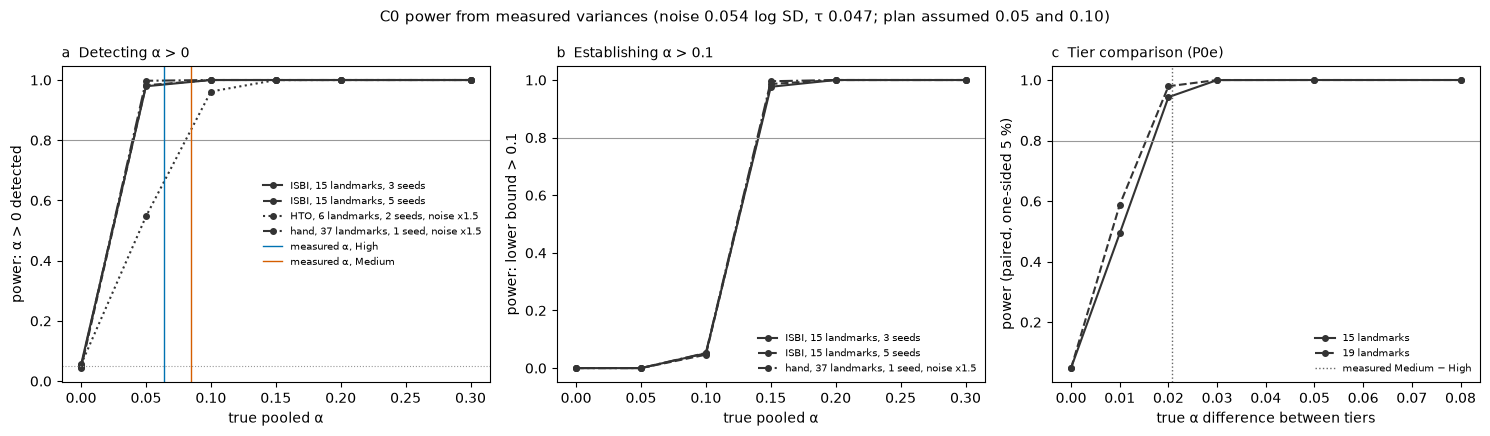

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axs[0]
for name, ls in [("ISBI, 15 landmarks, 3 seeds", "-"), ("ISBI, 15 landmarks, 5 seeds", "--"),
                 ("HTO, 6 landmarks, 2 seeds, noise x1.5", ":"), ("hand, 37 landmarks, 1 seed, noise x1.5", "-.")]:
    g = POWER[POWER.design == name]
    ax.plot(g.true_alpha, g.detect, ls, marker="o", ms=4, color="0.2", label=name)
ax.axhline(0.8, color="0.6", lw=0.8); ax.axhline(0.05, color="0.6", lw=0.8, ls=":")
for t in TIERS:
    ax.axvline(INPUTS[t]["alpha_mean"], color=COLORS[t], lw=1, label=f"measured α, {t}")
ax.set_xlabel("true pooled α"); ax.set_ylabel("power: α > 0 detected")
ax.set_title("a  Detecting α > 0", loc="left", fontsize=10); ax.legend(fontsize=7, frameon=False)
ax = axs[1]
for name, ls in [("ISBI, 15 landmarks, 3 seeds", "-"), ("ISBI, 15 landmarks, 5 seeds", "--"), ("hand, 37 landmarks, 1 seed, noise x1.5", "-.")]:
    g = POWER[POWER.design == name]
    ax.plot(g.true_alpha, g.established, ls, marker="o", ms=4, color="0.2", label=name)
ax.axhline(0.8, color="0.6", lw=0.8)
ax.set_xlabel("true pooled α"); ax.set_ylabel("power: lower bound > 0.1")
ax.set_title("b  Establishing α > 0.1", loc="left", fontsize=10); ax.legend(fontsize=7, frameon=False)
ax = axs[2]
for n_lm, ls in ((15, "-"), (19, "--")):
    g = POWER_E[POWER_E.n_landmarks == n_lm]
    ax.plot(g.true_diff, g.power_one_sided, ls, marker="o", ms=4, color="0.2", label=f"{n_lm} landmarks")
ax.axvline(INPUTS["paired_difference"]["mean_diff"], color="0.4", lw=1, ls=":", label="measured Medium − High")
ax.axhline(0.8, color="0.6", lw=0.8)
ax.set_xlabel("true α difference between tiers"); ax.set_ylabel("power (paired, one-sided 5 %)")
ax.set_title("c  Tier comparison (P0e)", loc="left", fontsize=10); ax.legend(fontsize=7, frameon=False)
fig.suptitle(f"C0 power from measured variances (noise {SIG:.3f} log SD, τ {TAU:.3f}; plan assumed 0.05 and 0.10)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "power_measured.png", dpi=150)